### LSE Data Analytics Online Career Accelerator 

# DA301:  Advanced Analytics for Organisational Impact

## Assignment template

### Scenario
You are a data analyst working for Turtle Games, a game manufacturer and retailer. They manufacture and sell their own products, along with sourcing and selling products manufactured by other companies. Their product range includes books, board games, video games and toys. They have a global customer base and have a business objective of improving overall sales performance by utilising customer trends. In particular, Turtle Games wants to understand: 
- how customers accumulate loyalty points (Week 1)
- exploring the structure using decision trees (Week 2)
- exploring clusters in customer behaviour (Week 3)
- can social data (e.g. customer reviews) be used in marketing campaigns (Week 4)
- loading, transforming and visualising data in R (Week 5)
- statistical analysis and modelling in R (Week 6)

# Week 1 assignment: Linear regression using Python
The marketing department of Turtle Games prefers Python for data analysis. As you are fluent in Python, they asked you to assist with data analysis of social media data. The marketing department wants to better understand how users accumulate loyalty points. Therefore, you need to investigate the possible relationships between the loyalty points, age, remuneration, and spending scores. Note that you will use this data set in future modules as well and it is, therefore, strongly encouraged to first clean the data as per provided guidelines and then save a copy of the clean data for future use.

## Instructions
1. Load and explore the data.
    1. Create a new DataFrame (e.g. reviews).
    2. Sense-check the DataFrame.
    3. Determine if there are any missing values in the DataFrame.
    4. Create a summary of the descriptive statistics.
2. Remove redundant columns (`language` and `platform`).
3. Change column headings to names that are easier to reference (e.g. `renumeration` and `spending_score`).
4. Save a copy of the clean DataFrame as a CSV file. Import the file to sense-check.
5. Use linear regression and goodness of fit metrics to evaluate possible linear relationships between loyalty points and age/renumeration/spending scores to determine whether these can be used to predict the loyalty points.
    1. Specify the independent and dependent variables.
    2. Create the OLS model.
    3. Extract the estimated parameters, standard errors, and predicted values.
    4. Generate the regression table based on the X coefficient and constant values.
    5. Plot the linear regression and add a regression line.
6. Include your insights and observations.

## 1. Load and explore the data

In [101]:
# Import all the necessary packages.
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.stats.api as sms
import sklearn
import matplotlib.pyplot as plt

from sklearn import linear_model
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LinearRegression
from statsmodels.formula.api import ols

import warnings  
warnings.filterwarnings('ignore')  

In [102]:
# Load the CSV file(s) as reviews.
reviews = pd.read_csv('turtle_reviews.csv')

# View the DataFrame.
reviews.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [103]:
# Any missing values?
reviews.isna().sum()

gender                    0
age                       0
remuneration (k£)         0
spending_score (1-100)    0
loyalty_points            0
education                 0
language                  0
platform                  0
product                   0
review                    0
summary                   0
dtype: int64

In [104]:
# Explore the data.
print(reviews.dtypes)

gender                     object
age                         int64
remuneration (k£)         float64
spending_score (1-100)      int64
loyalty_points              int64
education                  object
language                   object
platform                   object
product                     int64
review                     object
summary                    object
dtype: object


In [105]:
# View metadata
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   language                2000 non-null   object 
 7   platform                2000 non-null   object 
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   object 
 10  summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 172.0+ KB


In [106]:
# Basic descriptive statistics.
reviews.describe()

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


## 2. Drop columns

In [107]:
# Drop unnecessary columns.
reviews1 = reviews.drop(['language', 'platform'], axis = 1)   

# View the DataFrame.
reviews1.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 3. Rename columns

In [108]:
# Rename the column headers.
reviews_final = reviews1.rename(columns = {'remuneration (k£)' : 'remuneration',\
                                           'spending_score (1-100)' : 'spending_score'})

# Diplay new DataFrame
reviews_final.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 4. Save the DataFrame as a CSV file

In [109]:
# Create a CSV file as output.
reviews_final.to_csv('turtle_reviews_final.csv', header = True, index = False)

In [110]:
# Import new CSV file with Pandas.
reviews_lg = pd.read_csv('turtle_reviews_final.csv')

# View DataFrame.
reviews_lg.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 5. Linear regression

### 5a) age vs loyalty

In [111]:
# Define independent variable.
x_a = reviews_lg[['age']]

# Define dependent variable.
y_a = reviews_lg['loyalty_points']

# Specify the model
lr_a = LinearRegression()

# Fit the model
lr_a.fit(x_a, y_a)

LinearRegression()

In [112]:
# Extract the estimated parameters.
print('Intercept value: ', lr_a.intercept_)
print('Coefficient value: ', lr_a.coef_)

# Extract the predicted values.
pred_val_a = lr_a.predict(x_a)

print('Predicted values:\n', pred_val_a)

Intercept value:  1736.5177393990627
Coefficient value:  [-4.01280515]
Predicted values:
 [1664.2872467  1644.22322095 1648.2360261  ... 1600.0823643  1600.0823643
 1608.1079746 ]


In [113]:
# Set the X coefficient and the constant to generate the regression table.
x_const_a = sm.add_constant(x_a)
model_a = sm.OLS(y_a, x_const_a).fit()

# Extract the standard errors.
print('Standard errors:\n', model_a.bse)

Standard errors:
 const    88.248731
age       2.113177
dtype: float64


In [114]:
# View the regression table.
print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     3.606
Date:                Mon, 27 Jul 2026   Prob (F-statistic):             0.0577
Time:                        11:40:58   Log-Likelihood:                -17150.
No. Observations:                2000   AIC:                         3.430e+04
Df Residuals:                    1998   BIC:                         3.431e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1736.5177     88.249     19.678      0.0

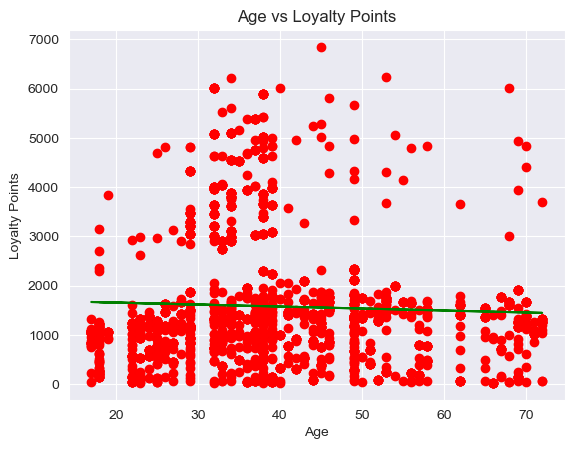

In [115]:
# Create a scatterplot with regression line.
plt.scatter(x_a, y_a, color = 'red') 
plt.plot(x_a, pred_val_a, color = 'green')

# Set the title and legends for the graph.  
plt.title("Age vs Loyalty Points")
plt.xlabel("Age")
plt.ylabel("Loyalty Points") 

# Print the graph. 
plt.show() 

The simple linear regression shows an extremely weak negative relationship between age and loyalty points. The model produced an R-squared value of 0.002, meaning age explains only 0.2% of the variation in loyalty points. Therefore, age is not a useful predictor of customer loyalty points.

### 5b) renumeration vs loyalty

In [116]:
# Define independent variable.
x_r = reviews_lg[['remuneration']]

# Define dependent variable.
y_r = reviews_lg['loyalty_points']

# Specify the model
lr_r = LinearRegression()

# Fit the model
lr_r.fit(x_r, y_r)

LinearRegression()

In [117]:
# Extract the estimated parameters.
print('Intercept value: ', lr_r.intercept_)
print('Coefficient value: ', lr_r.coef_)

# Extract the predicted values.
pred_val_r = lr_r.predict(x_r)

print('Predicted values:\n', pred_val_r)

Intercept value:  -65.68651279500409
Coefficient value:  [34.18782549]
Predicted values:
 [ 354.82374068  354.82374068  382.85775758 ... 3102.15739671 3298.39551499
 3102.15739671]


In [118]:
# Set the X coefficient and the constant to generate the regression table.
x_const_r = sm.add_constant(x_r)
model_r = sm.OLS(y_r, x_const_r).fit()

# Extract the standard errors.
print('Standard errors:\n', model_r.bse)

# Extract R-squared
print('R-squared: ', model_r.rsquared)

Standard errors:
 const           52.170717
remuneration     0.977925
dtype: float64
R-squared:  0.3795357732793635


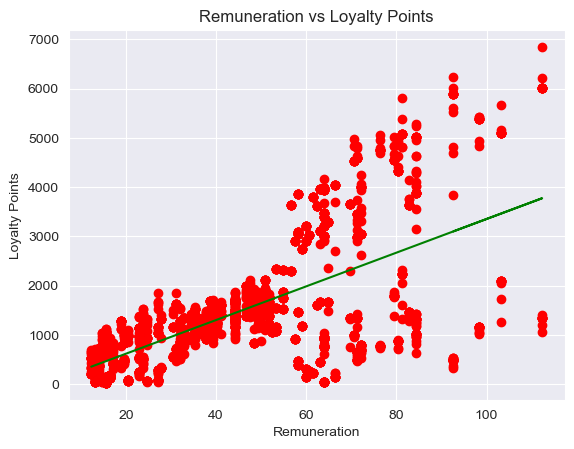

In [119]:
# Create a scatterplot with regression line.
plt.scatter(x_r, y_r, color = 'red') 
plt.plot(x_r, pred_val_r, color = 'green')

# Set the title and legends for the graph.  
plt.title("Remuneration vs Loyalty Points")
plt.xlabel("Remuneration")
plt.ylabel("Loyalty Points") 

# Print the graph. 
plt.show() 

The regression analysis indicates a moderate positive linear relationship between remuneration and loyalty points. The coefficient value of 34.19 suggests that each one-unit increase in remuneration is associated with an increase of approximately 34 loyalty points. The model produced an R-squared value of 0.3795, meaning remuneration explains around 38% of the variation in loyalty points, making it a substantially stronger predictor than age.

### 5c) spending score vs loyalty

In [120]:
# Define independent variable.
x_s = reviews_lg[['spending_score']]

# Define dependent variable.
y_s = reviews_lg['loyalty_points']

# Create model and print summary of metrics.
lr_s = LinearRegression()
lr_s.fit(x_s, y_s)

x_const_s = sm.add_constant(x_s)
model_s = sm.OLS(y_s, x_const_s).fit()

print(model_s.summary())

                            OLS Regression Results                            
Dep. Variable:         loyalty_points   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     1648.
Date:                Mon, 27 Jul 2026   Prob (F-statistic):          2.92e-263
Time:                        11:41:00   Log-Likelihood:                -16550.
No. Observations:                2000   AIC:                         3.310e+04
Df Residuals:                    1998   BIC:                         3.312e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -75.0527     45.931     -1.

In [121]:
# Extract the estimated parameters.
print('Intercept value: ', lr_s.intercept_)
print('Coefficient value: ', lr_s.coef_)

# Extract the predicted values.
pred_val_s = lr_s.predict(x_s)

print('Predicted values:\n', pred_val_s)

Intercept value:  -75.05266293364775
Coefficient value:  [33.06169326]
Predicted values:
 [1214.35337415 2602.94449102  123.31749662 ... 2933.56142361  453.93442921
  189.44088314]


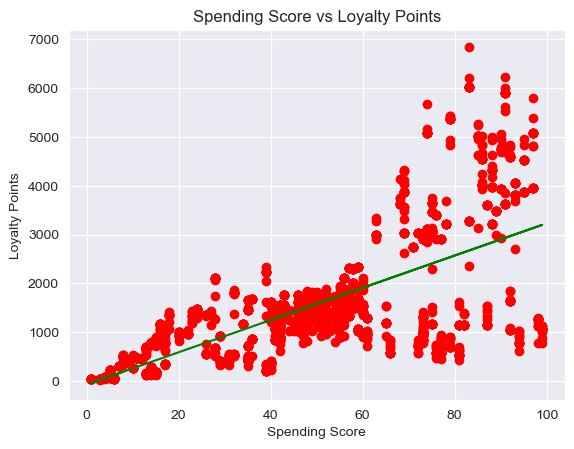

In [122]:
# Plot graph with regression line.
# Create a scatterplot with regression line.
plt.scatter(x_s, y_s, color = 'red') 
plt.plot(x_s, pred_val_s, color = 'green')

# Set the title and legends for the graph.  
plt.title("Spending Score vs Loyalty Points")
plt.xlabel("Spending Score")
plt.ylabel("Loyalty Points") 

# Print the graph. 
plt.show() 

## 6. Observations and insights

***Your observations here...***






Among the three predictors, spending score showed the strongest linear relationship with loyalty points (R² = 0.452), explaining approximately 45.2% of the variation in customer loyalty.
Remuneration also showed a moderate positive relationship (R² = 0.380), whereas age demonstrated almost no predictive power (R² = 0.002).
Therefore, spending behaviour appears to be the most useful variable for predicting customer loyalty points and should be prioritised in marketing strategies.

# Week 2 assignment: Exploring the structure using decision trees.

The team wants you to use decision trees to attempt to better understand the structure found in the data. You need to grow and prune a decision tree regressor and then visualise and interpret the output.
Make sure to comment on the potential usefulness in decision-making processes and your observations regarding the model.

## Instructions
1. Prepare the data for creating your decision tree. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame with the appropriate columns.
        1. Specify that loyalty points is the target variable (Y) and should be excluded from your input data.
        2. Specify X for the independent variables and y as the dependent variable. Therefore, df\[cols\] will be the independent variables and the column containing loyalty points the dependent variable.
        3. Explore the new DataFrame. 
2. Split the data set into a train and test sets for both X and y at a 70:30 ratio. As previously, random_state=42.
3. Create a decision tree regressor to explore the impact of other features on the loyalty points.
    1. Import the DecisionTreeRegressor class from the sklearn.tree library. 
    2. Create a variable (e.g. regressor) to store the DecisionTreeRegressor() class. (As previously, random_state=42.).
    3. Fit the regressor object to the data set with the fit() function.
    4. Remember to prune your tree using basic pruning strategies and compare the performance before and after applying the pruning strategy.
    5. Plot the final decision tree.
4. Fit a final model and interpret the output.
    1. Justify your selection of pruning strategy implemented and interpret the output.
    2. Evaluate the usefulness of the obtained result and interpret the tree and how it could be used to inform business decisions in the organisation.
5. Summarise (150–200 words) the most important business insights, anything you would like to explore further, and suggested future actions.
 
Back up your work to a safe location. This will allow you to revert to a previous state in the case of making a mistake in the code or deleting a section by mistake. (A simple way of doing this is to save or email a compressed version to yourself at frequent intervals.)


## 1. Load and prepare the data

In [123]:
# Import all the necessary packages
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree 
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import warnings
import matplotlib.pyplot as plt

# Settings for the notebook.
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = [15, 10]

In [124]:
# Create your new DataFrame.
df2 = pd.read_csv('turtle_reviews_final.csv')

# View the DataFrame
df2.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [125]:
# Check 'education' column values
df2['education'].value_counts()

education
graduate        900
PhD             460
postgraduate    400
diploma         190
Basic            50
Name: count, dtype: int64

In [126]:
# Encode gender
df2['gender'] = df2['gender'].map({'Male' : 0,
                                   'Female' : 1})

# Encode education
df2['education'] = df2['education'].map({'Basic' : 0,
                                         'diploma' : 1,
                                         'graduate' : 2,
                                         'postgraduate' : 3,
                                         'PhD' : 4})

df2.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,0,18,12.30,39,210,2,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,0,23,12.30,81,524,2,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,1,22,13.12,6,40,2,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,1,25,13.12,77,562,2,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,1,33,13.94,40,366,2,291,As my review of GF9's previous screens these w...,Money trap


In [127]:
# Specify Y.
y = df2['loyalty_points']
# Specify X.
X = df2.drop(['loyalty_points', 'review', 'summary'], axis = 1)

In [128]:
# Review X and Y.
print(X.shape)
print(y.shape)

(2000, 6)
(2000,)


## 2. Create train and test data sets.

In [129]:
# Split the data into test and train data.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 43)

## 3. Create Decision tree regressor

In [130]:
# Create your decision tree regressor.
regressor = DecisionTreeRegressor(random_state = 42)

# Fit the regressor object to the data set
regressor.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [131]:
# Evaluate the model.
train_score = regressor.score(X_train, y_train)
test_score = regressor.score(X_test, y_test)

print('Training Accuracy: ', train_score)
print('Testing Accuracy: ', test_score)

Training Accuracy:  1.0
Testing Accuracy:  0.9950588971974672


In [132]:
# Prune the model.
pruned_regressor = DecisionTreeRegressor(random_state = 42,
                                         max_depth = 4,
                                         min_samples_leaf = 20,
                                         min_samples_split = 20)

## 4. Fit and plot final model.

In [133]:
# Fit and final model.
pruned_regressor.fit(X_train, y_train)

# Compare the performance before and after pruning
print('Original Train Accuracy: ', regressor.score(X_train, y_train))
print('Original Test Accuracy: ', regressor.score(X_test, y_test))
print('Pruned Train Accuracy: ', pruned_regressor.score(X_train, y_train))
print('Pruned Test Accuracy: ', pruned_regressor.score(X_test, y_test))

Original Train Accuracy:  1.0
Original Test Accuracy:  0.9950588971974672
Pruned Train Accuracy:  0.9438847274359274
Pruned Test Accuracy:  0.9442904742711985


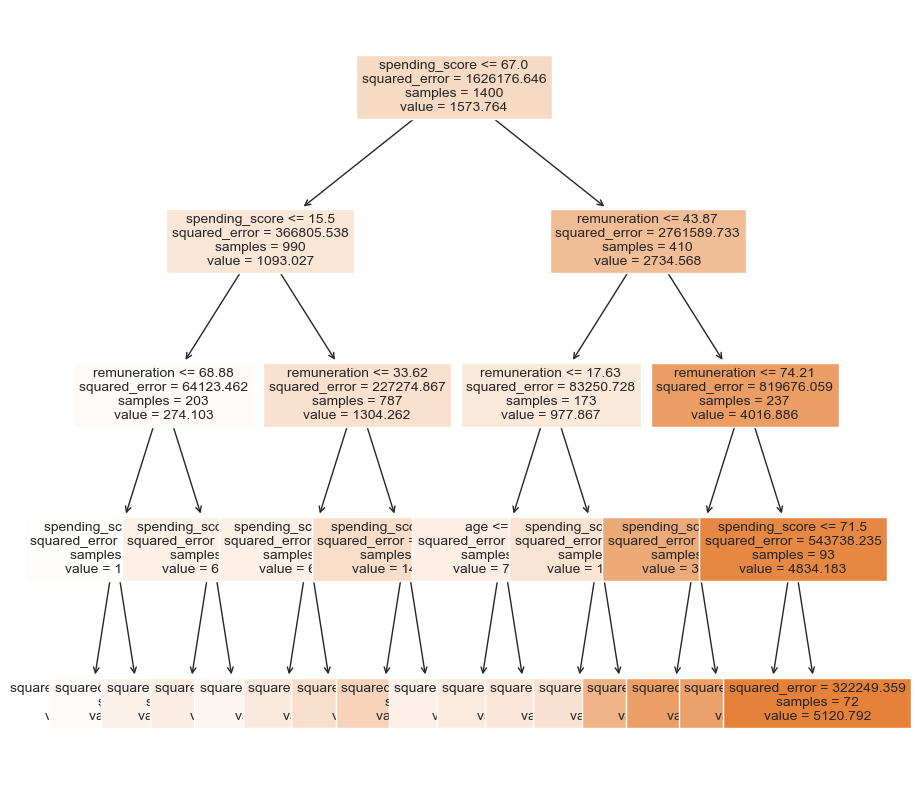

In [134]:
# Plot the final model
fig, ax = plt.subplots(figsize = (10, 10))

plot_tree(pruned_regressor,
          feature_names = X.columns,
          filled = True,
          fontsize = 10)

plt.savefig('Decision Tree.png')

# Print the plot
plt.show()

## 5. Discuss: Insights and observations

***Your observations here...***

In [135]:
# Interpret model and note observations.

The decision tree identifies spending_score as the most important predictor of loyalty points, followed by remuneration. Customers with higher spending scores generally have higher predicted loyalty points. The original model achieved a higher R² score than the pruned model, suggesting that pruning reduced predictive performance. These results could help the business identify high-value customers and develop more targeted loyalty and marketing strategies.

## Business insights

The decision tree shows that spending score is the strongest factor affecting customer loyalty points, followed by remuneration. Customers with higher spending scores generally have more loyalty points, and those with both high spending scores and higher remuneration are predicted to be the most valuable customers. This suggests that customers who spend more are also more engaged with the loyalty programme.

Although I applied pruning to simplify the model, the original model achieved better performance on both the training and test data. This suggests that pruning removed some useful information and slightly reduced the model's predictive ability. For this dataset, the original model would therefore be the better choice.

If I were to continue this analysis, I would explore whether other variables, such as customer reviews or product preferences, could improve the predictions. I would also compare the decision tree with other regression models to see whether even better results could be achieved. From a business perspective, these findings could help the organisation identify its highest-value customers, personalise loyalty offers and target marketing campaigns more effectively, improving customer retention and encouraging long-term engagement with the loyalty programme.

# 

# Week 3 assignment: Clustering with *k*-means using Python

The marketing department also wants to better understand the usefulness of renumeration and spending scores but do not know where to begin. You are tasked to identify groups within the customer base that can be used to target specific market segments. Use *k*-means clustering to identify the optimal number of clusters and then apply and plot the data using the created segments.

## Instructions
1. Prepare the data for clustering. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame (e.g. `df3`) containing the `renumeration` and `spending_score` columns.
    3. Explore the new DataFrame. 
2. Plot the renumeration versus spending score.
    1. Create a scatterplot.
    2. Create a pairplot.
3. Use the Silhouette and Elbow methods to determine the optimal number of clusters for *k*-means clustering.
    1. Plot both methods and explain how you determine the number of clusters to use.
    2. Add titles and legends to the plot.
4. Evaluate the usefulness of at least three values for *k* based on insights from the Elbow and Silhoutte methods.
    1. Plot the predicted *k*-means.
    2. Explain which value might give you the best clustering.
5. Fit a final model using your selected value for *k*.
    1. Justify your selection and comment on the respective cluster sizes of your final solution.
    2. Check the number of observations per predicted class.
6. Plot the clusters and interpret the model.

## 1. Load and explore the data

In [136]:
# Import necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')

In [137]:
# Load the CSV file(s)
df = pd.read_csv('turtle_reviews_final.csv')

# View DataFrame.
df.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [138]:
# Drop unnecessary columns.
df3 = df[['remuneration', 'spending_score']]

# View DataFrame.
df3.head()

,remuneration,spending_score
0,12.30,39
1,12.30,81
2,13.12,6
3,13.12,77
4,13.94,40


In [139]:
# Explore the data.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   remuneration    2000 non-null   float64
 1   spending_score  2000 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 31.4 KB


In [140]:
# Descriptive statistics.
df3.describe()

,remuneration,spending_score
count,2000.000000,2000.000000
mean,48.079060,50.000000
std,23.123984,26.094702
min,12.300000,1.000000
25%,30.340000,32.000000
50%,47.150000,50.000000
75%,63.960000,73.000000
max,112.340000,99.000000


## 2. Plot

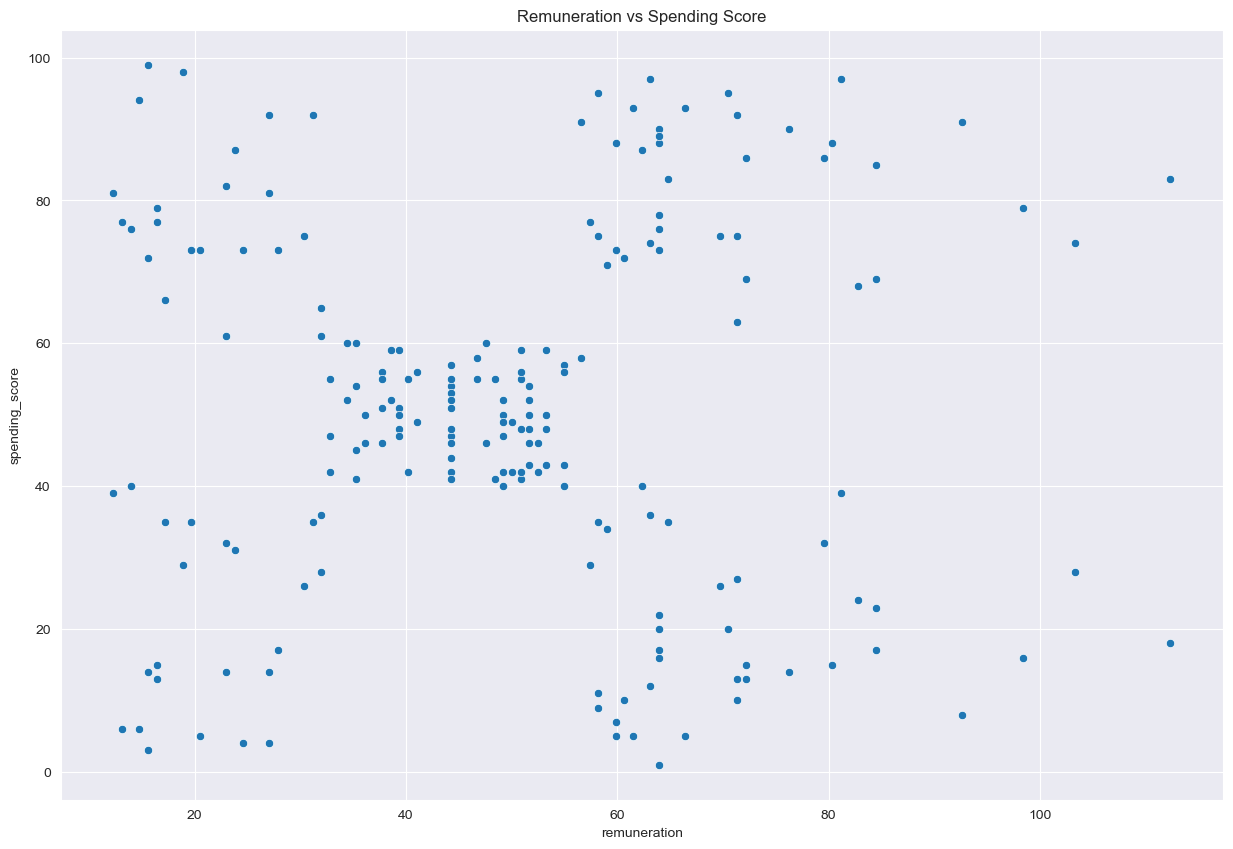

In [141]:
# Create a scatterplot with Seaborn.
sns.scatterplot(data = df3,
                x = 'remuneration',
                y = 'spending_score')

plt.title('Remuneration vs Spending Score')

plt.show()

The scatterplot shows little evidence of a strong relationship between remuneration and spending score. Instead, several distinct groups of customers appear to exist, suggesting that clustering techniques may be suitable for identifying different customer segments.

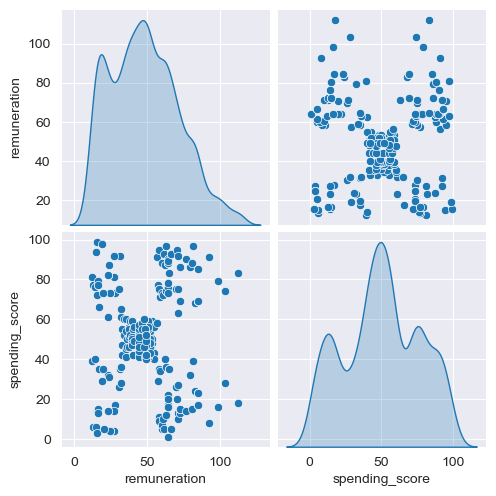

In [142]:
# Create a pairplot with Seaborn.
sns.pairplot(data = df3,
             diag_kind = 'kde')

plt.show()

Although remuneration and spending score do not appear to have a strong linear relationship, the visualisations suggest several distinct customer segments. This indicates that customers with similar incomes may display very different spending behaviours. Identifying these segments could help Turtle Games tailor marketing campaigns, personalise promotions and allocate resources more effectively to different customer groups.

## 3. Elbow and silhoutte methods

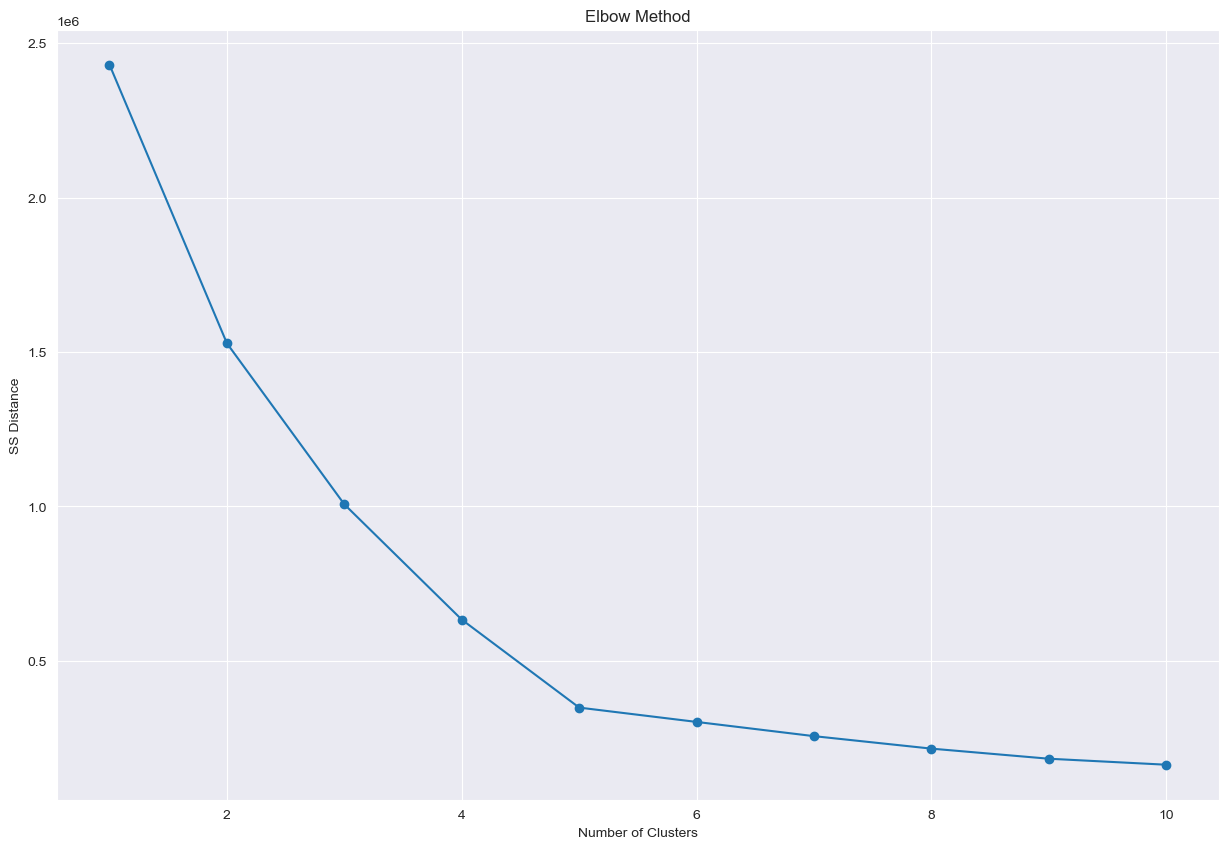

In [143]:
# Determine the number of clusters: Elbow method.
ss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters = i,
                    init='k-means++',
                    max_iter = 500,
                    n_init = 10,
                    random_state = 42)
    kmeans.fit(df3)
    ss.append(kmeans.inertia_)

plt.plot(range(1, 11), ss, marker = 'o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('SS Distance')

plt.show()

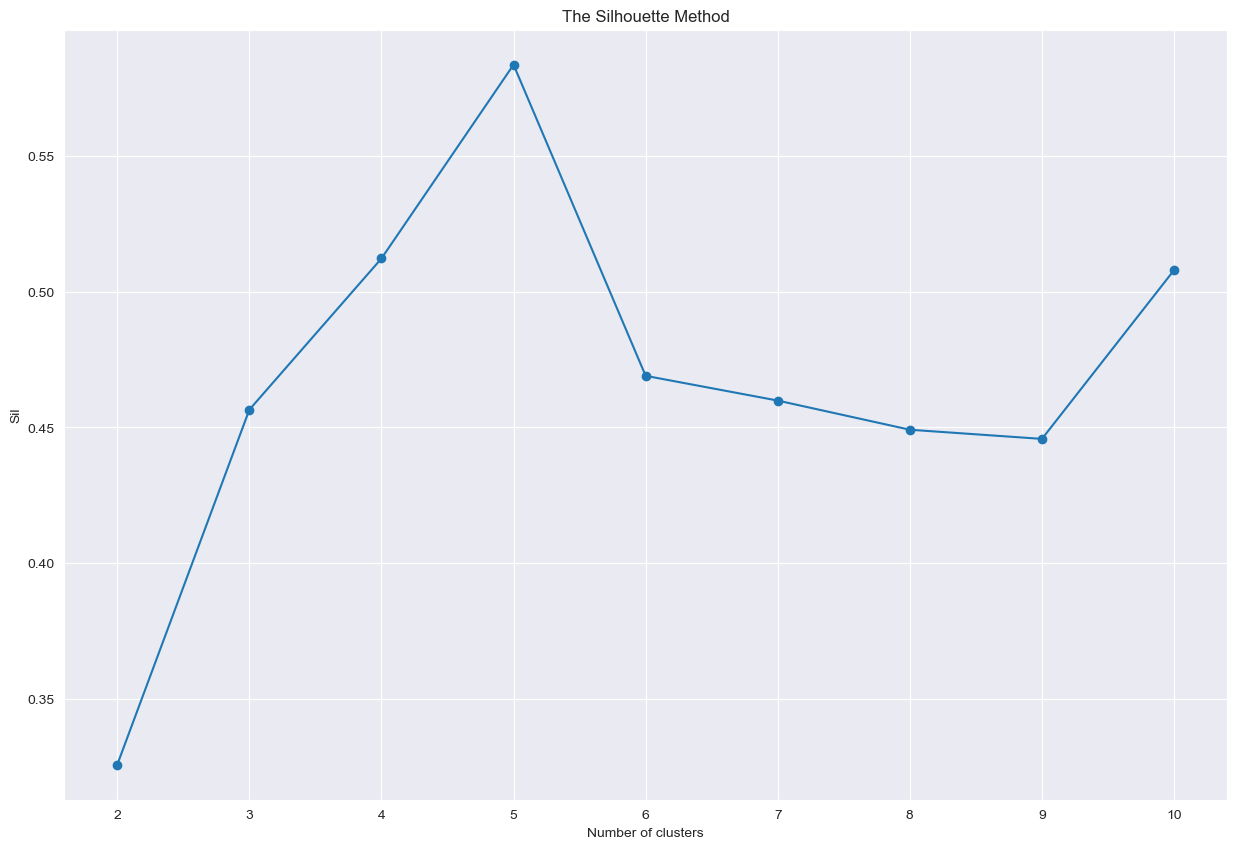

In [144]:
# Determine the number of clusters: Silhouette method.
sil = []
kmax = 10

for k in range(2, kmax + 1):
    kmeans_s = KMeans(n_clusters=k).fit(df3)
    labels = kmeans_s.labels_
    sil.append(silhouette_score(df3,
                                labels,
                                metric = 'euclidean'))

# Plot the silhouette method
plt.plot(range(2, kmax + 1),
         sil,
         marker = 'o')

# Insert labels and title
plt.title('The Silhouette Method')
plt.xlabel('Number of clusters')
plt.ylabel('Sil')

plt.show()

## 4. Evaluate k-means model at different values of *k*

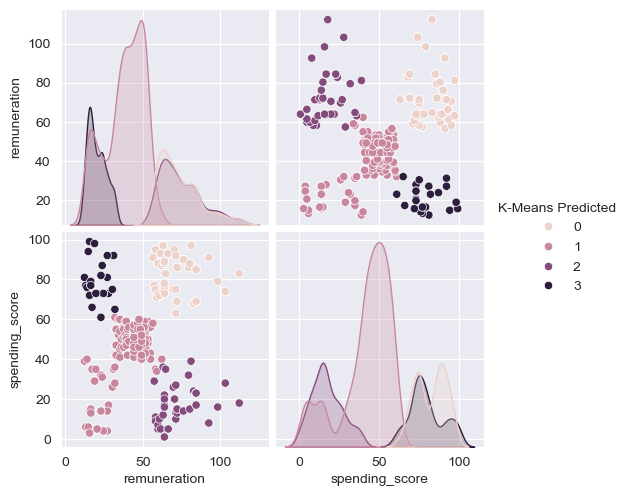

K-Means Predicted
1    1045
0     356
2     330
3     269
Name: count, dtype: int64

In [145]:
# Evaluate and fit model with 4 clusters
kmeans = KMeans(n_clusters = 4,
                init = 'k-means++',
                max_iter = 500,
                random_state = 42)

kmeans.fit(df3)

# Create predicted cluster
clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

sns.pairplot(df3,
             hue = 'K-Means Predicted',
             diag_kind = 'kde')

plt.show()

# Print number of observations per predicted clss
df3['K-Means Predicted'].value_counts()

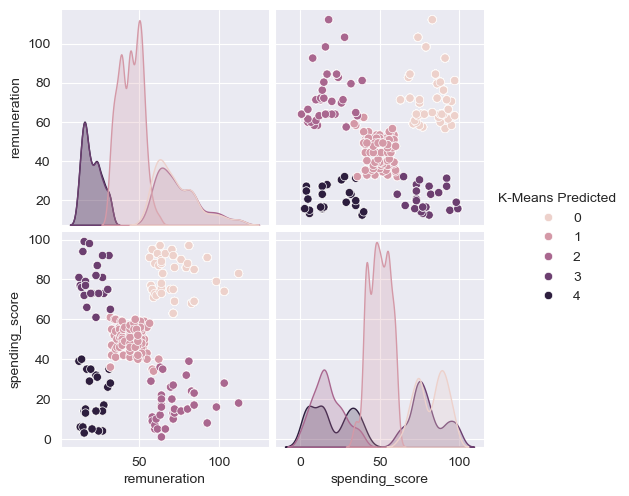

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

In [146]:
# Evaluate and fit model with 5 clusters
kmeans = KMeans(n_clusters = 5,
                init = 'k-means++',
                max_iter = 500,
                random_state = 42)

kmeans.fit(df3)

# Create predicted cluster
clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

sns.pairplot(df3,
             hue = 'K-Means Predicted',
             diag_kind = 'kde')

plt.show()

# Print number of observations per predicted clss
df3['K-Means Predicted'].value_counts()

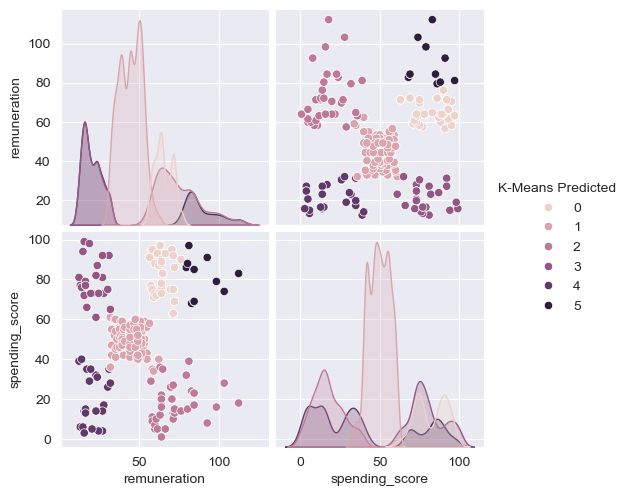

K-Means Predicted
1    774
2    330
4    271
3    269
0    238
5    118
Name: count, dtype: int64

In [147]:
# Evaluate and fit model with 6 clusters
kmeans = KMeans(n_clusters = 6,
                init = 'k-means++',
                max_iter = 500,
                random_state = 42)

kmeans.fit(df3)

# Create predicted cluster
clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

sns.pairplot(df3,
             hue = 'K-Means Predicted',
             diag_kind = 'kde')

plt.show()

# Print number of observations per predicted class
df3['K-Means Predicted'].value_counts()

## 5. Fit final model and justify your choice

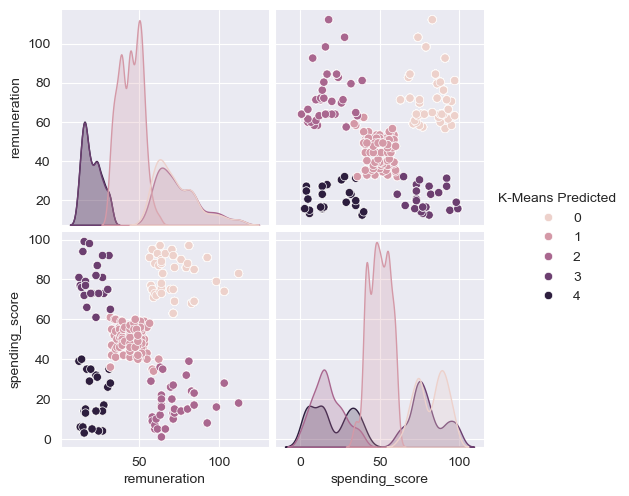

In [148]:
# Apply the final model.
kmeans = KMeans(n_clusters = 5,
                init = 'k-means++',
                max_iter = 500,
                random_state = 42)

kmeans.fit(df3)

# Create predicted cluster
clusters = kmeans.labels_
df3['K-Means Predicted'] = clusters

sns.pairplot(df3,
             hue = 'K-Means Predicted',
             diag_kind = 'kde')

In [149]:
# Check the number of observations per predicted class.
df3['K-Means Predicted'].value_counts()

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

Both the Elbow and Silhouette methods were used to identify the optimal number of clusters. The Elbow Method suggested that the improvement in inertia began to level off at around five clusters, indicating that adding additional clusters beyond this point would provide only limited improvement. The Silhouette Method also supported this choice, producing the highest score at k = 5, which indicates the best separation and cohesion between clusters. Finally, visual inspection of the pairplots showed that the five-cluster solution produced well-defined and meaningful customer segments. Compared with four clusters, the five-cluster model separated customers with similar remuneration but different spending behaviours more effectively. When six clusters were tested, an additional small cluster was created with only 118 customers, suggesting that the data had been over-segmented without providing substantial additional insight. Therefore, the five-cluster solution provides the best balance between statistical performance, clear visual separation and practical business interpretation.

## 6. Plot and interpret the clusters

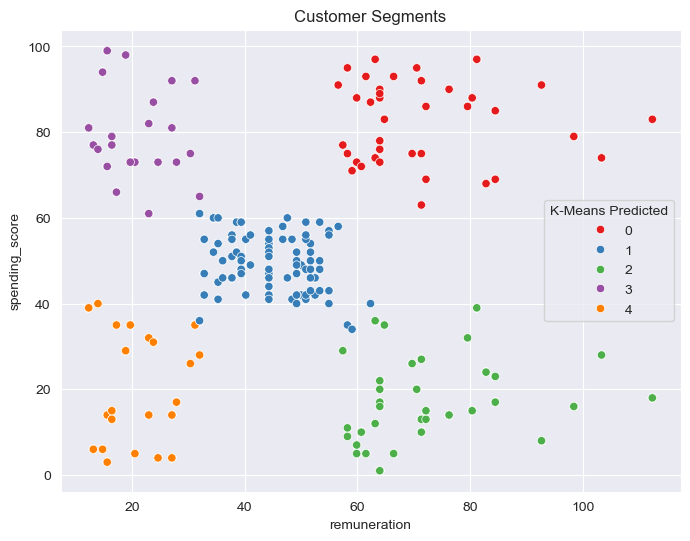

,remuneration,spending_score,K-Means Predicted
0,12.30,39,4
1,12.30,81,3
2,13.12,6,4
3,13.12,77,3
4,13.94,40,4
...,...,...,...
1995,84.46,69,0
1996,92.66,8,2
1997,92.66,91,0
1998,98.40,16,2


In [188]:
# Visualising the clusters.
plt.figure(figsize = (8, 6))

sns.scatterplot(data = df3,
                x = 'remuneration',
                y = 'spending_score',
                hue = 'K-Means Predicted',
                palette = 'Set1')

plt.title('Customer Segments')

plt.savefig('Customer Segments.png')

plt.show()

# View the DataFrame.
df3

## 7. Discuss: Insights and observations

***Your observations here...***

## Overall observations
- The five-cluster solution has produced distinct customer segments with minimal overlap
- Customers with similar remuneration often have very different spending behaviours, showing that remuneration alone does not explain customer purchasing habits
- The clustering model successfully identifies groups that could be targeted with different marketing strategies

The five-cluster solution identified clear customer segments based on remuneration and spending score. The clusters represent customers with different spending behaviours despite similar income levels, demonstrating that remuneration alone is not a reliable predictor of spending. These insights could help Turtle Games personalise marketing campaigns, improve customer retention and focus promotional activities on the most valuable customer groups.

# 

# Week 4 assignment: NLP using Python
Customer reviews were downloaded from the website of Turtle Games. This data will be used to steer the marketing department on how to approach future campaigns. Therefore, the marketing department asked you to identify the 15 most common words used in online product reviews. They also want to have a list of the top 20 positive and negative reviews received from the website. Therefore, you need to apply NLP on the data set.

## Instructions
1. Load and explore the data. 
    1. Sense-check the DataFrame.
    2. You only need to retain the `review` and `summary` columns.
    3. Determine if there are any missing values.
2. Prepare the data for NLP
    1. Change to lower case and join the elements in each of the columns respectively (`review` and `summary`).
    2. Replace punctuation in each of the columns respectively (`review` and `summary`).
    3. Drop duplicates in both columns (`review` and `summary`).
3. Tokenise and create wordclouds for the respective columns (separately).
    1. Create a copy of the DataFrame.
    2. Apply tokenisation on both columns.
    3. Create and plot a wordcloud image.
4. Frequency distribution and polarity.
    1. Create frequency distribution.
    2. Remove alphanumeric characters and stopwords.
    3. Create wordcloud without stopwords.
    4. Identify 15 most common words and polarity.
5. Review polarity and sentiment.
    1. Plot histograms of polarity (use 15 bins) for both columns.
    2. Review the sentiment scores for the respective columns.
6. Identify and print the top 20 positive and negative reviews and summaries respectively.
7. Include your insights and observations.

## 1. Load and explore the data

In [151]:
# Import all the necessary packages.
import pandas as pd
import numpy as np
import nltk 
import os 
import matplotlib.pyplot as plt

nltk.download('punkt_tab')
nltk.download('stopwords')

from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm

# Import Counter.
from collections import Counter

import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [152]:
# Load the CSV file(s)
df4 = pd.read_csv('turtle_reviews_final.csv')

# View DataFrame.
df4.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [153]:
# Keep necessary columns. Drop unnecessary columns.
df_reviews = df4[['review', 'summary']]

# View DataFrame.
df_reviews.head()

,review,summary
0,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,As my review of GF9's previous screens these w...,Money trap


In [154]:
# Determine if there are any missing values.
df_reviews.isnull().sum()

review     0
summary    0
dtype: int64

## 2. Prepare the data for NLP
### 2a) Change to lower case and join the elements in each of the columns respectively (review and summary)

In [155]:
# Review: Change all to lower case and join with a space.
df_reviews['review'] = df_reviews['review'].apply(lambda x: ' '.join(x.lower() for x in x.split()))

In [156]:
# Summary: Change all to lower case and join with a space.
df_reviews['summary'] = df_reviews['summary'].apply(lambda x: ' '.join(x.lower() for x in x.split()))

### 2b) Replace punctuation in each of the columns respectively (review and summary)

In [157]:
# Replace all the punctuations in review column.
df_reviews['review'] = df_reviews['review'].str.replace(r'[^\w\s]', '', regex = True)

# View output.
df_reviews['review'].head()

0    when it comes to a dms screen the space on the...
1    an open letter to galeforce9 your unpainted mi...
2    nice art nice printing why two panels are fill...
3    amazing buy bought it as a gift for our new dm...
4    as my review of gf9s previous screens these we...
Name: review, dtype: object

In [158]:
# Replace all the puncuations in summary column.
df_reviews['summary'] = df_reviews['summary'].str.replace(r'[^\w\s]', '', regex = True)

# View output.
df_reviews['summary'].head()

0    the fact that 50 of this space is wasted on ar...
1    another worthless dungeon masters screen from ...
2                       pretty but also pretty useless
3                                           five stars
4                                           money trap
Name: summary, dtype: object

### 2c) Drop duplicates in both columns

In [159]:
# Drop duplicates in both columns.
df_reviews_final = df_reviews.drop_duplicates(subset=['review'])
df_reviews_final = df_reviews_final.drop_duplicates(subset=['summary'])
df_reviews_final.reset_index(inplace = True)

# View DataFrame.
df_reviews_final.head()

,index,review,summary
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless
3,3,amazing buy bought it as a gift for our new dm...,five stars
4,4,as my review of gf9s previous screens these we...,money trap


## 3. Tokenise and create wordclouds

In [160]:
# Create new DataFrame (copy DataFrame).
df_nlp = df_reviews_final.copy()

# View DataFrame.
df_nlp.head()

,index,review,summary
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless
3,3,amazing buy bought it as a gift for our new dm...,five stars
4,4,as my review of gf9s previous screens these we...,money trap


In [161]:
# Apply tokenisation to both columns.
df_nlp['review_tokens'] = df_nlp['review'].apply(word_tokenize)
df_nlp['summary_tokens'] = df_nlp['summary'].apply(word_tokenize)


# View DataFrame.
df_nlp.head()

,index,review,summary,review_tokens,summary_tokens
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,"[when, it, comes, to, a, dms, screen, the, spa...","[the, fact, that, 50, of, this, space, is, was..."
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,"[an, open, letter, to, galeforce9, your, unpai...","[another, worthless, dungeon, masters, screen,..."
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless,"[nice, art, nice, printing, why, two, panels, ...","[pretty, but, also, pretty, useless]"
3,3,amazing buy bought it as a gift for our new dm...,five stars,"[amazing, buy, bought, it, as, a, gift, for, o...","[five, stars]"
4,4,as my review of gf9s previous screens these we...,money trap,"[as, my, review, of, gf9s, previous, screens, ...","[money, trap]"


In [162]:
# Review: Create a word cloud.
review_text = ' '.join(df_nlp['review'])

review_wc = WordCloud(width = 1600,
                       height = 900,
                       background_color = 'white',
                       colormap = 'plasma',
                       min_font_size = 10).generate(review_text)                       

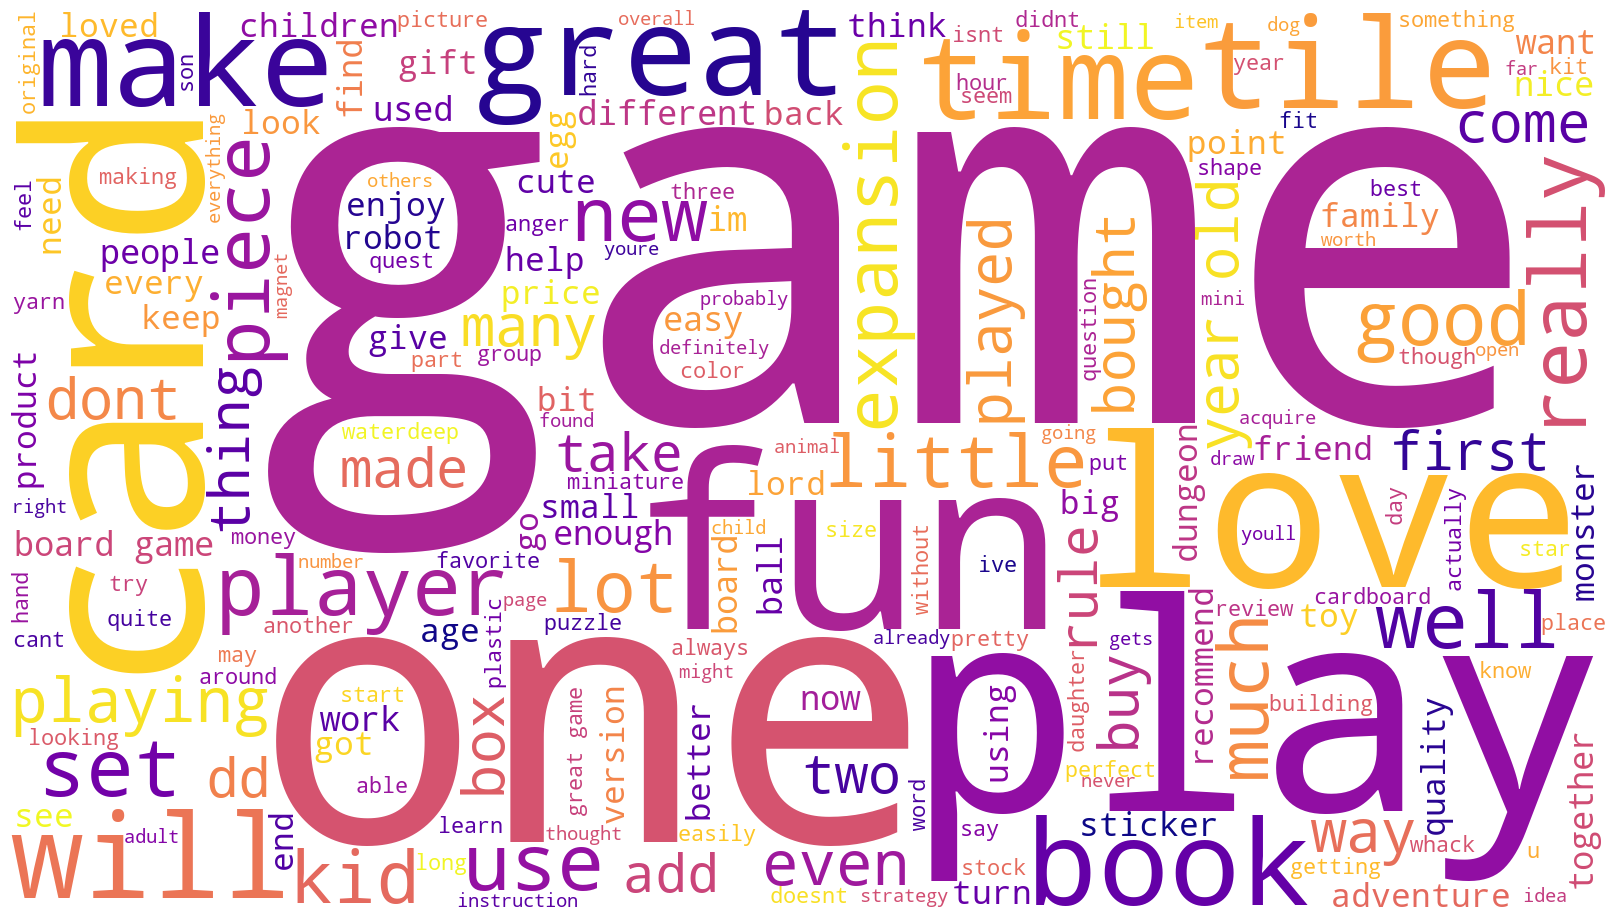

In [163]:
# Review: Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(review_wc)
plt.axis('off')
plt.tight_layout(pad = 0)
plt.show()

In [164]:
# Summary: Create a word cloud.
summary_text = ' '.join(df_nlp['summary'])

summary_wc = WordCloud(width = 1600,
                       height = 900,
                       background_color = 'white',
                       colormap = 'plasma',
                       min_font_size = 10).generate(summary_text)    

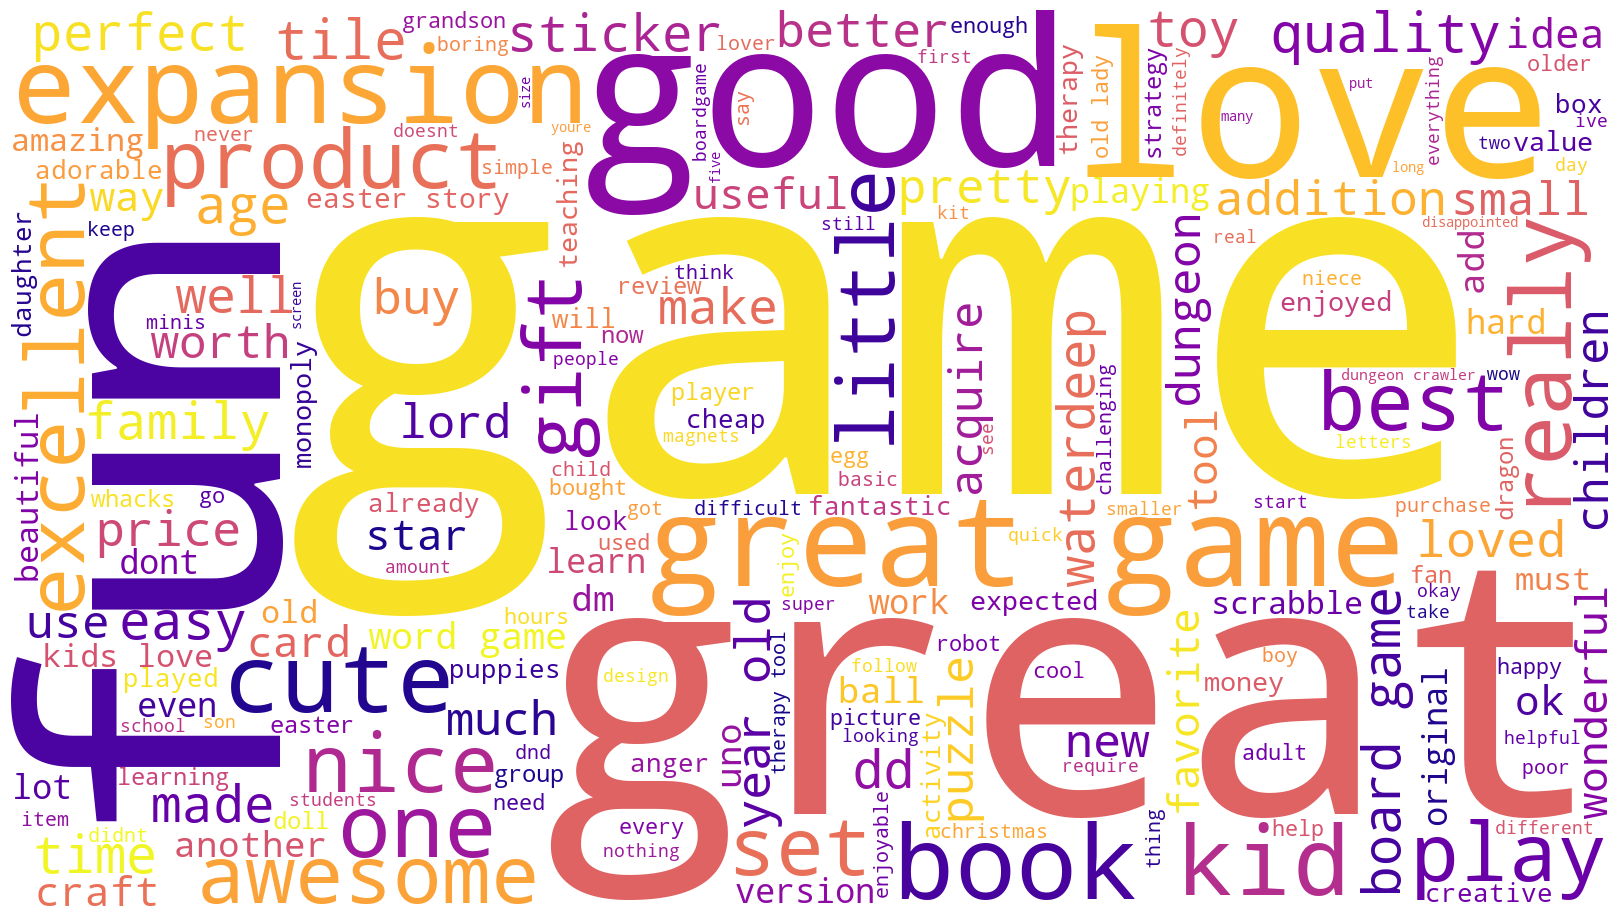

In [165]:
# Summary: Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(summary_wc)
plt.axis('off')
plt.tight_layout(pad = 0)
plt.show()

## 4. Frequency distribution and polarity
### 4a) Create frequency distribution

In [166]:
# Determine the frequency distribution for 'review' column

# Define an empty list of tokens.
review_tokens = []

for i in range(df_nlp.shape[0]):
    # Add each review taken to the list.
    review_tokens = review_tokens + df_nlp['review_tokens'][i]

# Calculate the frequency distribution.
rewiew_fdist = FreqDist(review_tokens)

# Preview data.
review_fdist

FreqDist({'the': 5451, 'and': 3233, 'to': 3162, 'a': 3160, 'of': 2488, 'i': 2090, 'it': 2083, 'is': 1782, 'this': 1776, 'game': 1671, ...})

In [167]:
# Determine the frequency distribution for 'summary' column

# Define an empty list of tokens.
summary_tokens = []

for i in range(df_nlp.shape[0]):
    # Add each review taken to the list.
    summary_tokens = summary_tokens + df_nlp['summary_tokens'][i]

# Calculate the frequency distribution.
summary_fdist = FreqDist(summary_tokens)

# Preview data.
summary_fdist

FreqDist({'game': 268, 'the': 257, 'a': 238, 'great': 236, 'for': 229, 'to': 192, 'fun': 175, 'and': 168, 'it': 139, 'of': 131, ...})

### 4b) Remove alphanumeric characters and stopwords

In [168]:
# Delete all the alphanum and stopwords from 'review' column
stop_words = set(stopwords.words('english'))

clean_review_tokens = [word for word in review_tokens
                       if word.isalpha() and word not in stop_words]

In [169]:
# Delete all the alphanum and stopwords from 'summary' column
clean_summary_tokens = [word for word in summary_tokens
                       if word.isalpha() and word not in stop_words]

### 4c) Create wordcloud without stopwords

In [170]:
# Create a wordcloud without stop words for 'review' column
clean_review_text = ' '.join(clean_review_tokens)

word_cloud_r = WordCloud(width = 1600,
                       height = 900,
                       background_color = 'white',
                       colormap = 'plasma',
                       min_font_size = 10).generate(clean_review_text)    

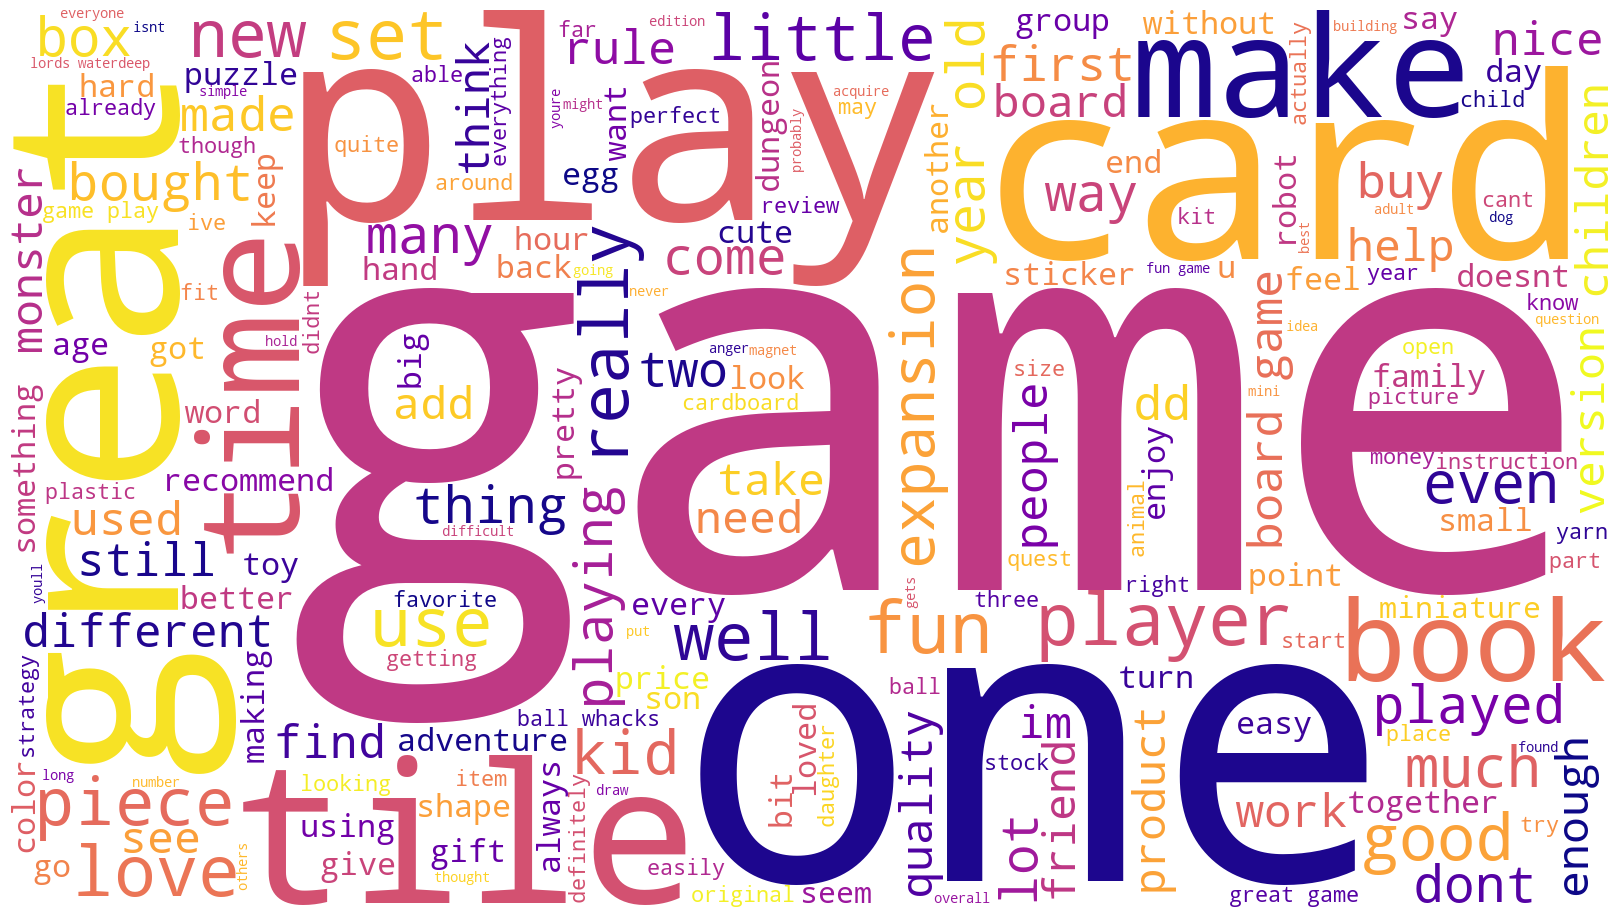

In [171]:
# Plot the wordcloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(word_cloud_r)
plt.axis('off')
plt.tight_layout(pad = 0)

plt.savefig("WordCloud.png")
plt.show()

In [172]:
# Create a wordcloud without stop words for 'summary' column
clean_summary_text = ' '.join(clean_summary_tokens)

word_cloud_s = WordCloud(width = 1600,
                       height = 900,
                       background_color = 'white',
                       colormap = 'plasma',
                       min_font_size = 10).generate(clean_summary_text)    

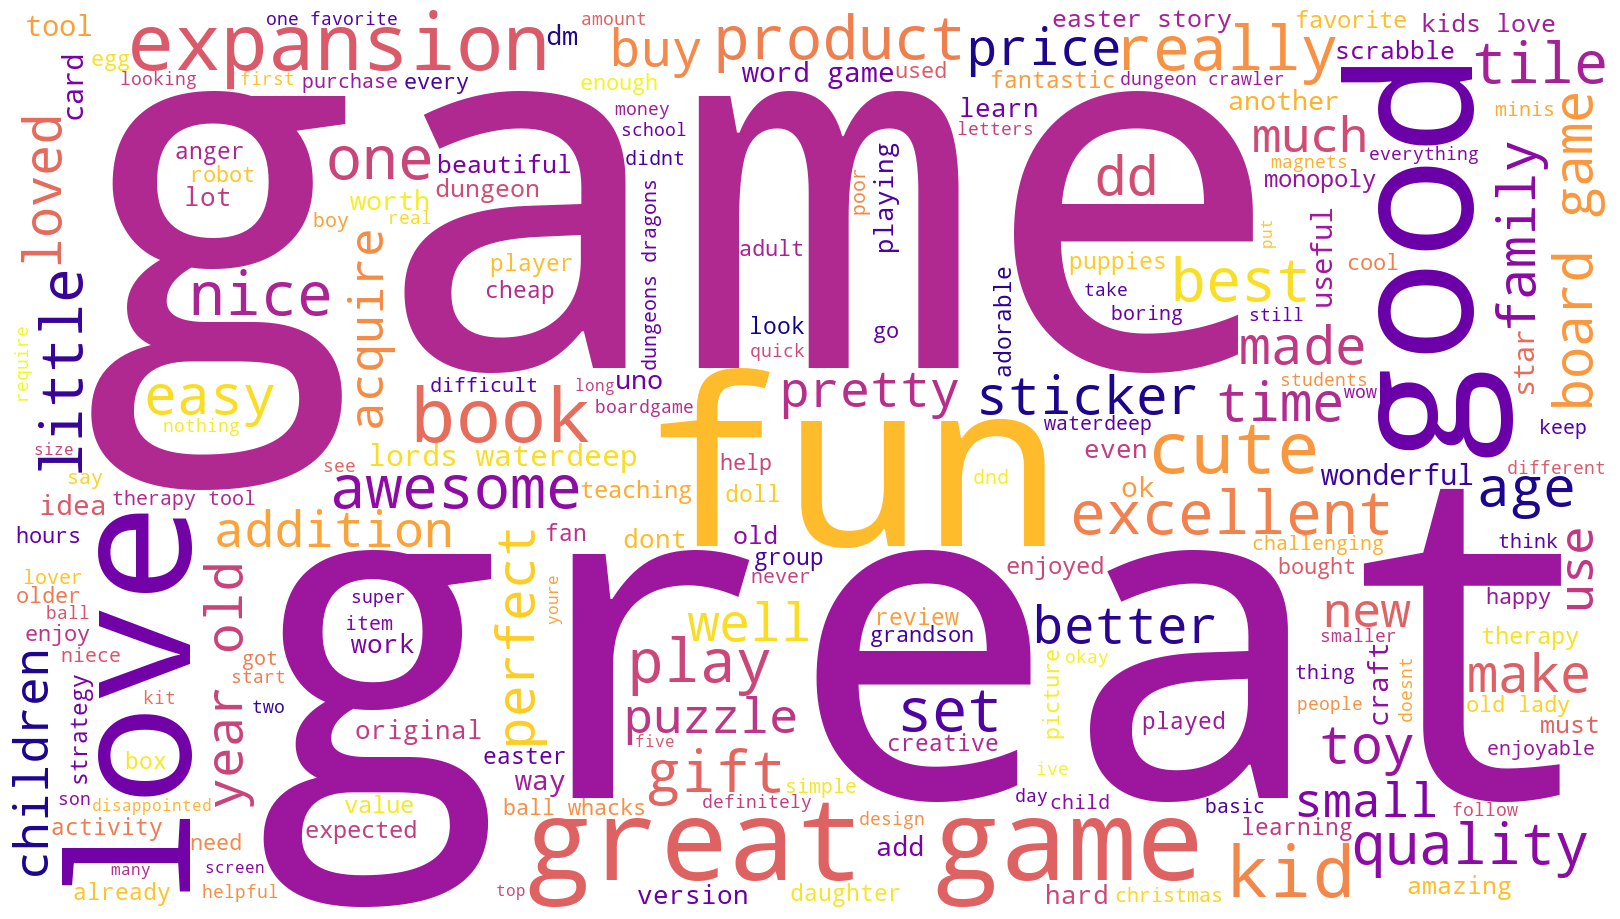

In [173]:
# Plot the wordcloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(word_cloud_s)
plt.axis('off')
plt.tight_layout(pad = 0)
plt.show()

### 4d) Identify 15 most common words and polarity

In [174]:
# Determine the 15 most common words for 'review' column
counts_review = pd.DataFrame(Counter(clean_review_tokens).most_common(15),
                             columns = ['Word', 'Frequency']).set_index('Word')

# Preview data
counts_review

,Frequency
Word,
game,1359
one,475
play,442
fun,407
great,391
like,373
get,293
cards,281
tiles,280


In [175]:
# Determine the 15 most common words for 'summary' column
counts_summary = pd.DataFrame(Counter(clean_summary_tokens).most_common(15),
                             columns = ['Word', 'Frequency']).set_index('Word')

# Preview data
counts_summary

,Frequency
Word,
game,268
great,236
fun,175
good,84
love,70
like,54
kids,48
book,42
expansion,42


## 5. Review polarity and sentiment: Plot histograms of polarity (use 15 bins) and sentiment scores for the respective columns.

In [176]:
# Provided function.
def generate_polarity(comment):
    '''Extract polarity score (-1 to +1) for each comment'''
    return TextBlob(comment).sentiment[0]

In [177]:
# Determine polarity of both columns. 
df_nlp['review_polarity'] = df_nlp['review'].apply(generate_polarity)
df_nlp['summary_polarity'] = df_nlp['summary'].apply(generate_polarity)

# View output.
df_nlp.head()

,index,review,summary,review_tokens,summary_tokens,review_polarity,summary_polarity
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,"[when, it, comes, to, a, dms, screen, the, spa...","[the, fact, that, 50, of, this, space, is, was...",-0.036111,0.15
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,"[an, open, letter, to, galeforce9, your, unpai...","[another, worthless, dungeon, masters, screen,...",0.035952,-0.80
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless,"[nice, art, nice, printing, why, two, panels, ...","[pretty, but, also, pretty, useless]",0.116640,0.00
3,3,amazing buy bought it as a gift for our new dm...,five stars,"[amazing, buy, bought, it, as, a, gift, for, o...","[five, stars]",0.578788,0.00
4,4,as my review of gf9s previous screens these we...,money trap,"[as, my, review, of, gf9s, previous, screens, ...","[money, trap]",-0.316667,0.00


In [178]:
# Subjectivity function
def generate_subjectivity(comment):
    '''Extract subjectivity score (0 to 1)'''
    return TextBlob(comment).sentiment[1]

In [179]:
# Determine subjectivity for both columns.
df_nlp['review_subjectivity'] = df_nlp['review'].apply(generate_subjectivity)
df_nlp['summary_subjectivity'] = df_nlp['summary'].apply(generate_subjectivity)

# Analyze subjectivity score for 'review' column
df_nlp['review_subjectivity'].describe()

count    1349.000000
mean        0.513432
std         0.162243
min         0.000000
25%         0.432164
50%         0.500833
75%         0.599242
max         1.000000
Name: review_subjectivity, dtype: float64

In [180]:
# Analyze subjectivity score for 'summary' column
df_nlp['summary_subjectivity'].describe()

count    1349.000000
mean        0.483263
std         0.312286
min         0.000000
25%         0.200000
50%         0.516667
75%         0.733333
max         1.000000
Name: summary_subjectivity, dtype: float64

The average subjectivity score for the reviews is 0.513, indicating that they are moderately subjective and mainly express personal opinions. The summaries have a slightly lower average score of 0.483, suggesting they are slightly more objective. However, the higher standard deviation for the summaries (0.312) shows that their subjectivity varies more than the reviews, with some being highly objective and others highly subjective.

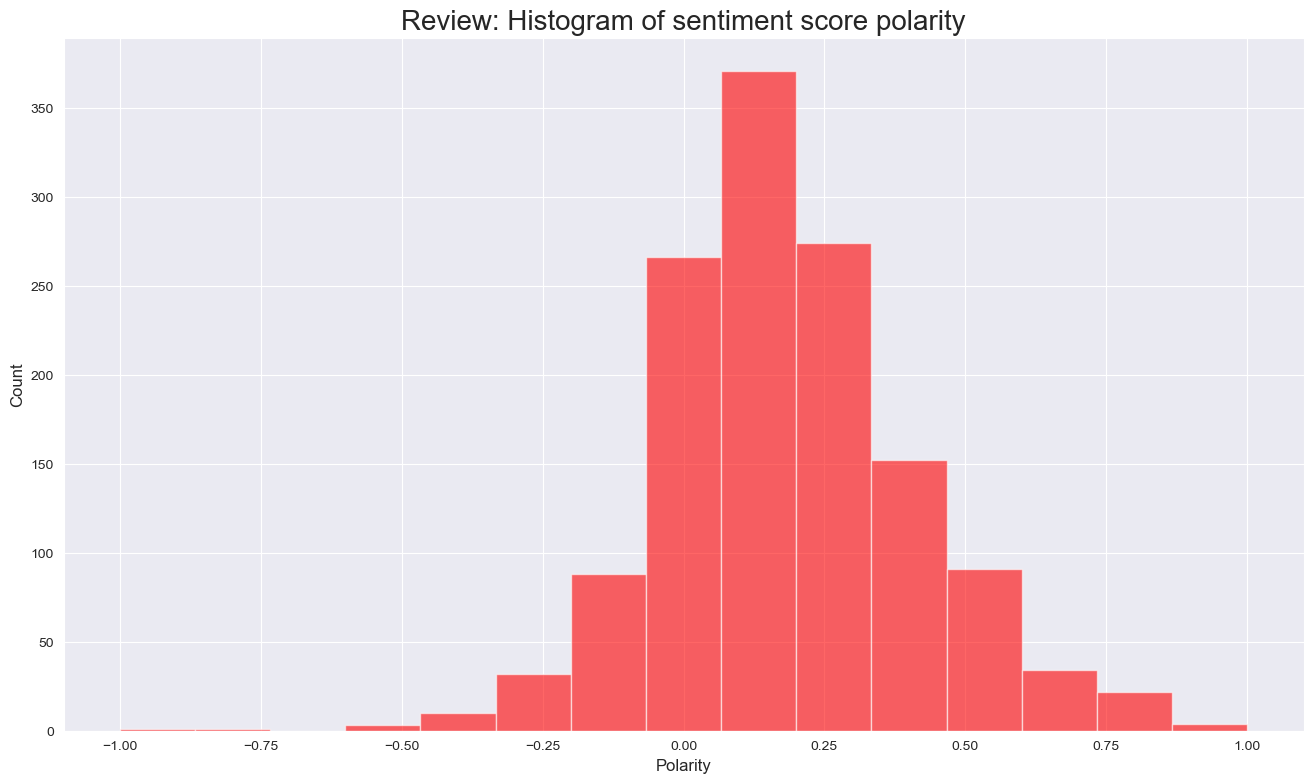

In [181]:
# Import Seaborn
import seaborn as sns

# Set plot style
sns.set_style("darkgrid")

# Review: Create a histogram plot with bins = 15.
# Histogram of polarity
# Set the number of bins
num_bins = 15

# Set the plot area
plt.figure(figsize = (16, 9))

# Define the bars
n, bins, patches = plt.hist(df_nlp['review_polarity'],
                            num_bins,
                            facecolor = 'red',
                            alpha = 0.6)

# Set the labels
plt.xlabel('Polarity', fontsize = 12)
plt.ylabel('Count', fontsize = 12)
plt.title('Review: Histogram of sentiment score polarity', fontsize = 20)

plt.savefig("Sentiment Histogram.png")

plt.show()

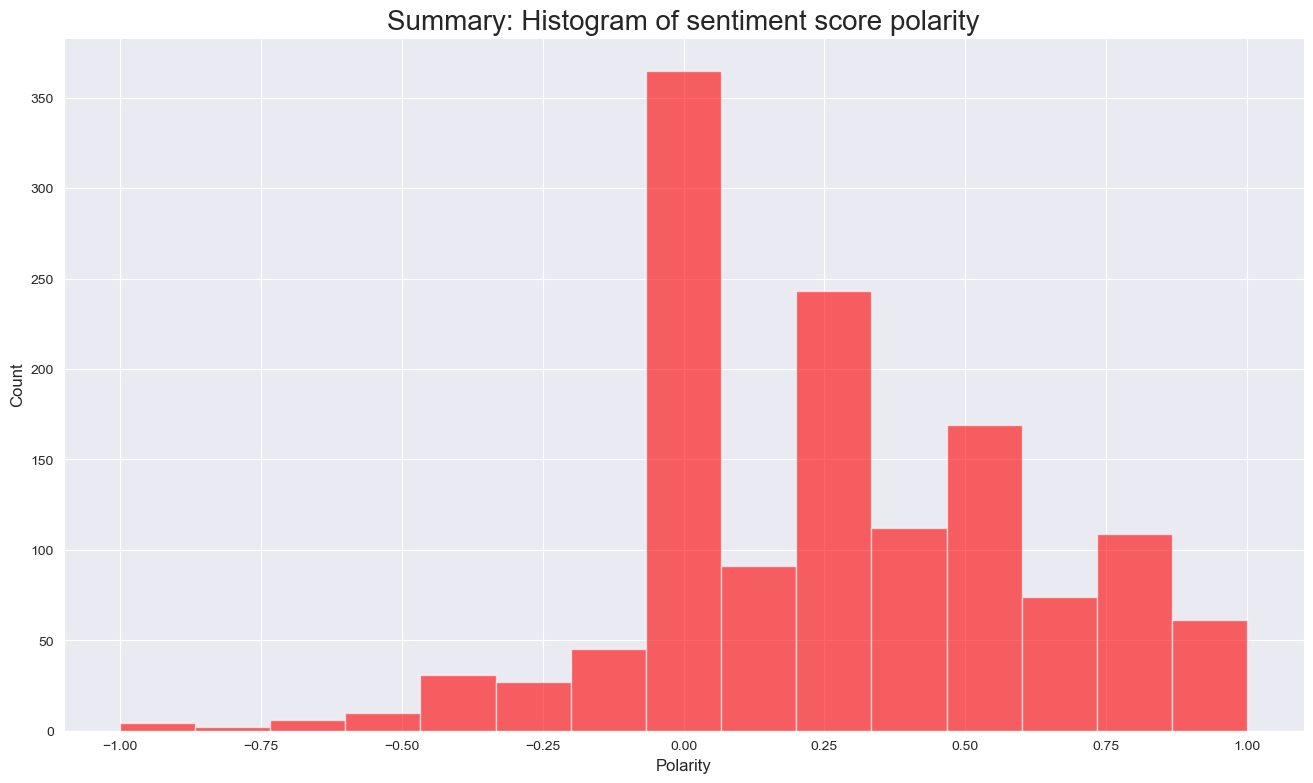

In [182]:
# Summary: Create a histogram plot with bins = 15.
# Histogram of polarity
# Set the plot area
plt.figure(figsize = (16, 9))

# Define the bars
n, bins, patches = plt.hist(df_nlp['summary_polarity'],
                            num_bins,
                            facecolor = 'red',
                            alpha = 0.6)

# Set the labels
plt.xlabel('Polarity', fontsize = 12)
plt.ylabel('Count', fontsize = 12)
plt.title('Summary: Histogram of sentiment score polarity', fontsize = 20)

plt.show()

## 6. Identify top 20 positive and negative reviews and summaries respectively

In [183]:
# Top 20 negative reviews.
top20_negative_reviews = df_nlp.sort_values(by = 'review_polarity',
                                            ascending = True).head(20)

# View output.
top20_negative_reviews[['review', 'review_polarity']]

,review,review_polarity
165,booo unles you are patient know how to measure...,-1.000000
147,incomplete kit very disappointing,-0.780000
267,one of my staff will be using this game soon s...,-0.550000
90,i bought this as a christmas gift for my grand...,-0.500000
141,i sent this product to my granddaughter the po...,-0.491667
251,my 8 yearold granddaughter and i were very fru...,-0.446250
382,i purchased this on the recommendation of two ...,-0.440741
713,if you like me used to play dd but now you and...,-0.400000
1011,you can play the expansions one at a time or a...,-0.400000
355,my son loves playing this game it was recommen...,-0.400000


In [184]:
# Top 20 negative summaries.
top20_negative_summaries = df_nlp.sort_values(by = 'summary_polarity',
                                            ascending = True).head(20)

# View output.
top20_negative_summaries[['summary', 'summary_polarity']]

,summary,summary_polarity
165,boring unless you are a craft person which i am,-1.000000
587,boring,-1.000000
17,the worst value ive ever seen,-1.000000
837,before this i hated running any rpg campaign d...,-0.900000
1,another worthless dungeon masters screen from ...,-0.800000
116,disappointed,-0.750000
266,promotes anger instead of teaching calming met...,-0.700000
637,bad qualityall made of paper,-0.700000
634,too bad this is not what i was expecting,-0.700000
144,at age 31 i found these very difficult to make,-0.650000


In [185]:
# Top 20 positive reviews.
top20_positive_reviews = df_nlp.sort_values(by = 'review_polarity',
                                            ascending = False).head(20)

# View output.
top20_positive_reviews[['review', 'review_polarity']]

,review,review_polarity
564,perfect,1.000000
1080,my daughter loves her stickers awesome seller ...,1.000000
1334,perfect for tutoring my grandson in spelling,1.000000
890,the best part i see is the box what a wonderfu...,0.880000
498,great quality very cute and perfect for my tod...,0.816667
1333,this is a great tool to have at hand when play...,0.800000
336,great seller happy with my purchase 5 starrrr,0.800000
1287,prompt service and a great product,0.800000
1187,a great creation tool it helps me concentrate,0.800000
824,husband seems happy with it,0.800000


In [186]:
# Top 20 positive summaries.
top20_positive_summaries = df_nlp.sort_values(by = 'summary_polarity',
                                            ascending = False).head(20)

# View output.
top20_positive_summaries[['summary', 'summary_polarity']]

,summary,summary_polarity
150,awesome,1.0
541,perfect tool for learning how to tell time one...,1.0
337,excellent,1.0
581,one of the best games ever,1.0
1080,awesome seller thank you,1.0
776,best dungeon crawler,1.0
1078,loves stickers and she loves peppa so this wa...,1.0
982,awesome expansion,1.0
720,best one in the series,1.0
737,excellent introduction to dungeons and dragons,1.0


## 7. Discuss: Insights and observations

The text analysis indicates that customer sentiment towards Turtle Games' products is generally positive. The sentiment histogram shows that most reviews have positive polarity scores, with relatively few strongly negative reviews. Word frequency analysis highlights terms such as game, fun, great, good and love, suggesting that customers value enjoyable gameplay and positive user experiences. Frequently occurring words including cards, tiles, kids and expansion indicate that product components, family use and additional game content are important to customers. The most positive reviews praise product quality, educational value and suitability as gifts, while the most negative reviews commonly mention poor quality, confusing instructions, incomplete products and unmet expectations. Subjectivity analysis shows that reviews are largely based on personal experiences, providing valuable insight into customer opinions. Future analysis could group reviews by product category or identify recurring themes within negative feedback to better understand customer concerns. Turtle Games should continue to build on the features customers value most while addressing common quality and usability issues to improve customer satisfaction and strengthen future product development.